# 01. Exploration du trafic Internet (Milan, Telecom Italia)

Objectifs : comprendre la structure de la série (tendance, saisonnalités, anomalies) pour guider le choix des modèles.
Série étudiée : activité Internet horaire de toute la zone, en heure de Milan.
Rappel : les valeurs sont relatives (facteur d'échelle gardé secret par l'opérateur).

module://matplotlib_inline.backend_inline


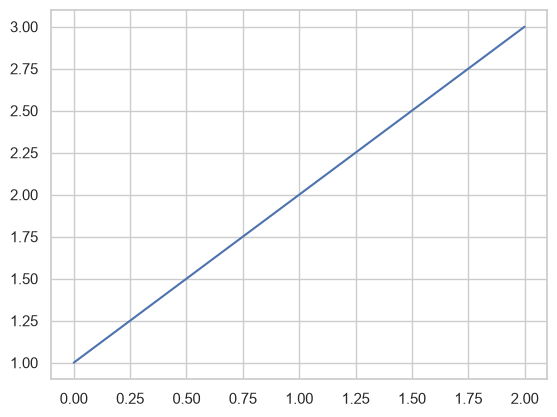

In [10]:
import matplotlib
print(matplotlib.get_backend())
import matplotlib.pyplot as plt
plt.plot([1, 2, 3]); plt.show()

In [11]:
# #installaions
# %pip install statsmodels seaborn scipy pandas numpy matplotlib

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

sns.set_theme(style="whitegrid")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

s = pd.read_csv(ROOT / "data" / "processed" / "traffic_zone_1h.csv", index_col=0)
s.index = pd.to_datetime(s.index, utc=True).tz_convert("Europe/Rome")
s = s["internet"].asfreq("1h")
print(f"{len(s)} points du {s.index.min()} au {s.index.max()}")
print(f"Heures manquantes : {int(s.isna().sum())}")
s.describe()

1488 points du 2013-11-01 00:00:00+01:00 au 2014-01-01 23:00:00+01:00
Heures manquantes : 0


count    1.488000e+03
mean     3.731784e+06
std      1.335347e+06
min      1.263443e+06
25%      2.472994e+06
50%      3.834889e+06
75%      4.861324e+06
max      6.297268e+06
Name: internet, dtype: float64

## 1. Vue d'ensemble

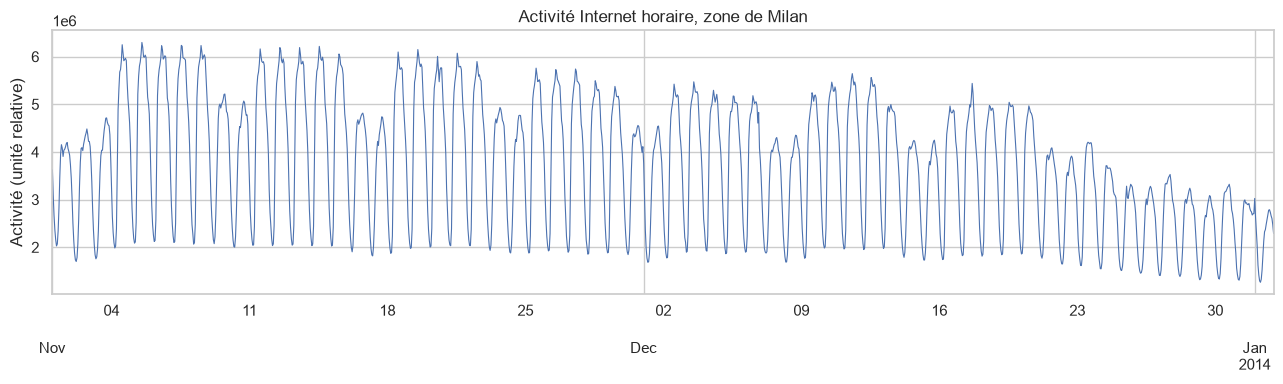

In [13]:
fig, ax = plt.subplots(figsize=(13, 4))
s.plot(ax=ax, lw=0.8)
ax.set_title("Activité Internet horaire, zone de Milan")
ax.set_ylabel("Activité (unité relative)")
fig.tight_layout(); fig.savefig(FIG / "01_serie_complete.png", dpi=150)

## 2. Profil journalier : semaine contre week-end

C:\Users\Cheick\AppData\Local\Temp\ipykernel_15976\1310607422.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df["weekend"] = np.where(df.index.dayofweek >= 5, "week-end", "semaine")


Heure de pointe moyenne : 17 h


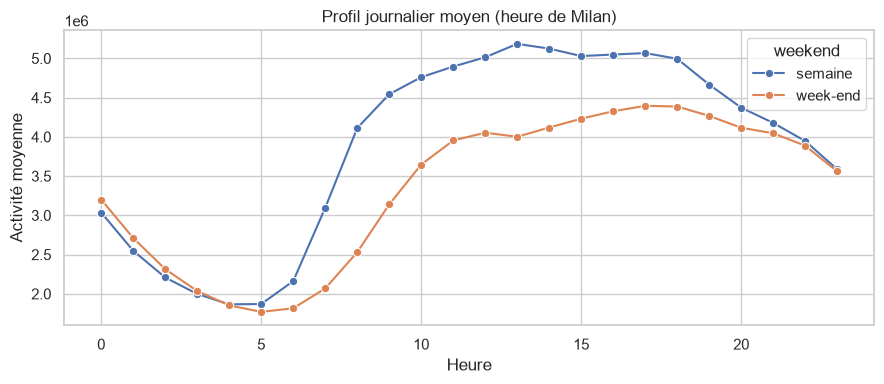

In [14]:
df = s.to_frame("internet")
df["hour"] = df.index.hour
df["weekend"] = np.where(df.index.dayofweek >= 5, "week-end", "semaine")
profile = df.groupby(["weekend", "hour"])["internet"].mean().reset_index()

fig, ax = plt.subplots(figsize=(9, 4))
sns.lineplot(data=profile, x="hour", y="internet", hue="weekend", marker="o", ax=ax)
ax.set_title("Profil journalier moyen (heure de Milan)")
ax.set_xlabel("Heure"); ax.set_ylabel("Activité moyenne")
fig.tight_layout(); fig.savefig(FIG / "02_profil_journalier.png", dpi=150)
print("Heure de pointe moyenne :", df.groupby("hour")["internet"].mean().idxmax(), "h")

## 3. Carte jour x heure : repérer les jours atypiques

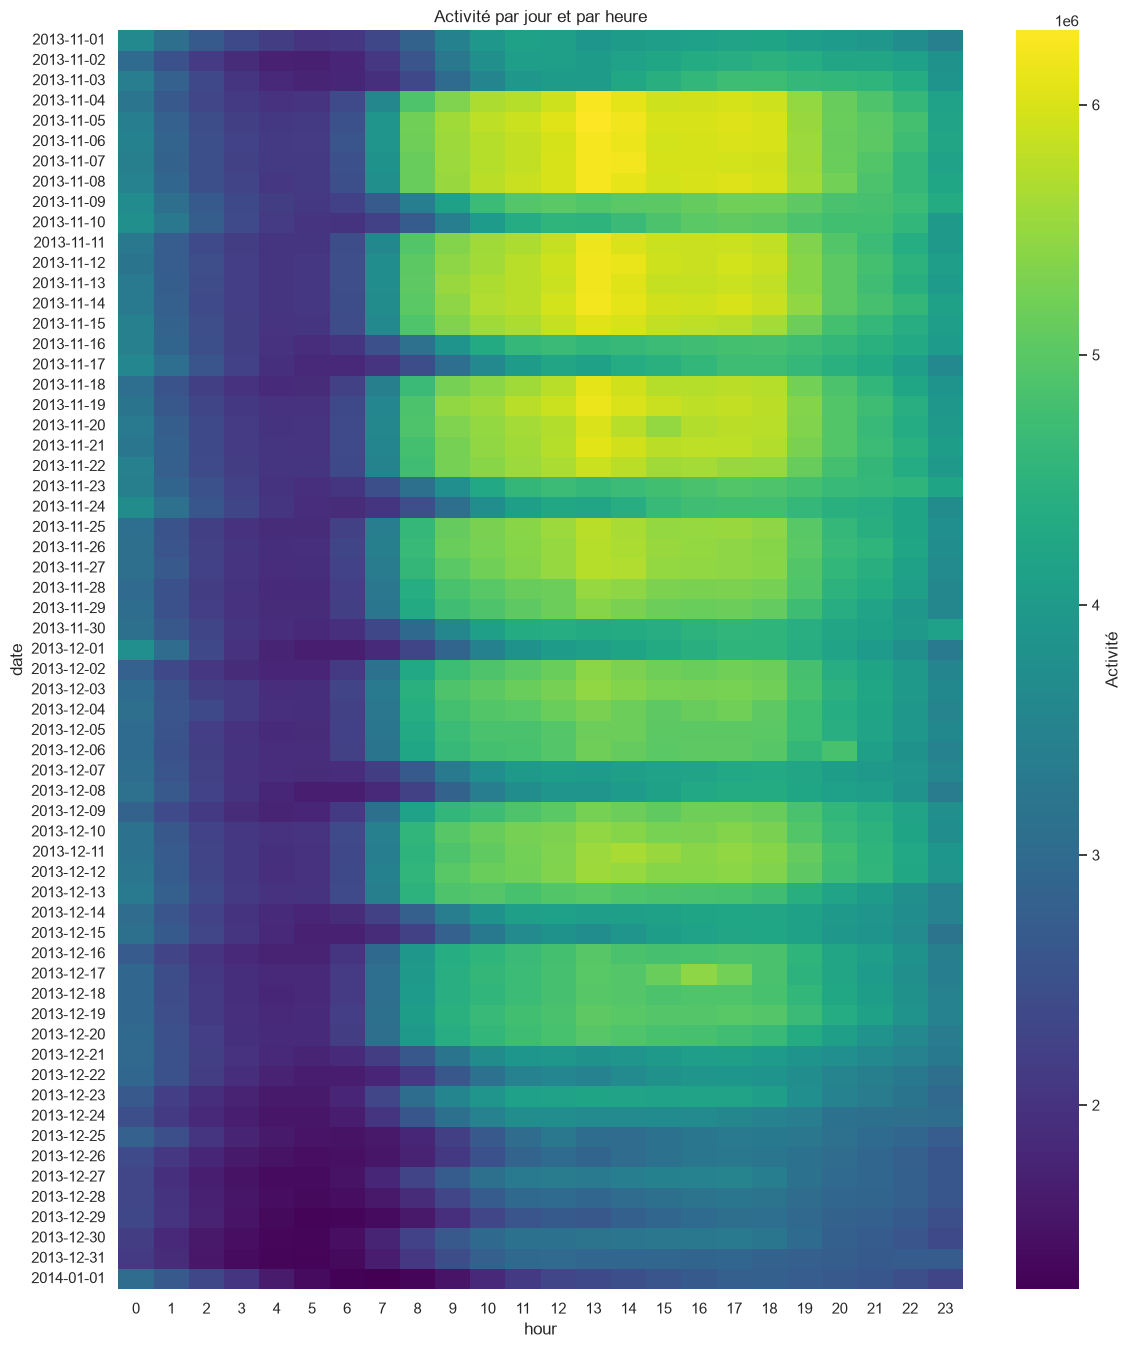

In [15]:
heat = df.assign(date=df.index.date).pivot_table(index="date", columns="hour", values="internet")
fig, ax = plt.subplots(figsize=(12, max(3, len(heat) * 0.22)))
sns.heatmap(heat, cmap="viridis", ax=ax, cbar_kws={"label": "Activité"})
ax.set_title("Activité par jour et par heure")
fig.tight_layout(); fig.savefig(FIG / "03_heatmap_jour_heure.png", dpi=150)

## 4. Décomposition tendance, saisonnalité, résidu
STL (robuste aux valeurs aberrantes) avec une saisonnalité journalière (24 h). Si la série couvre au moins deux semaines, on ajoute la saisonnalité hebdomadaire (168 h) avec MSTL.

Décomposition MSTL (24 h et 168 h)
Force de la saisonnalité (journalière + hebdomadaire) : 0.99


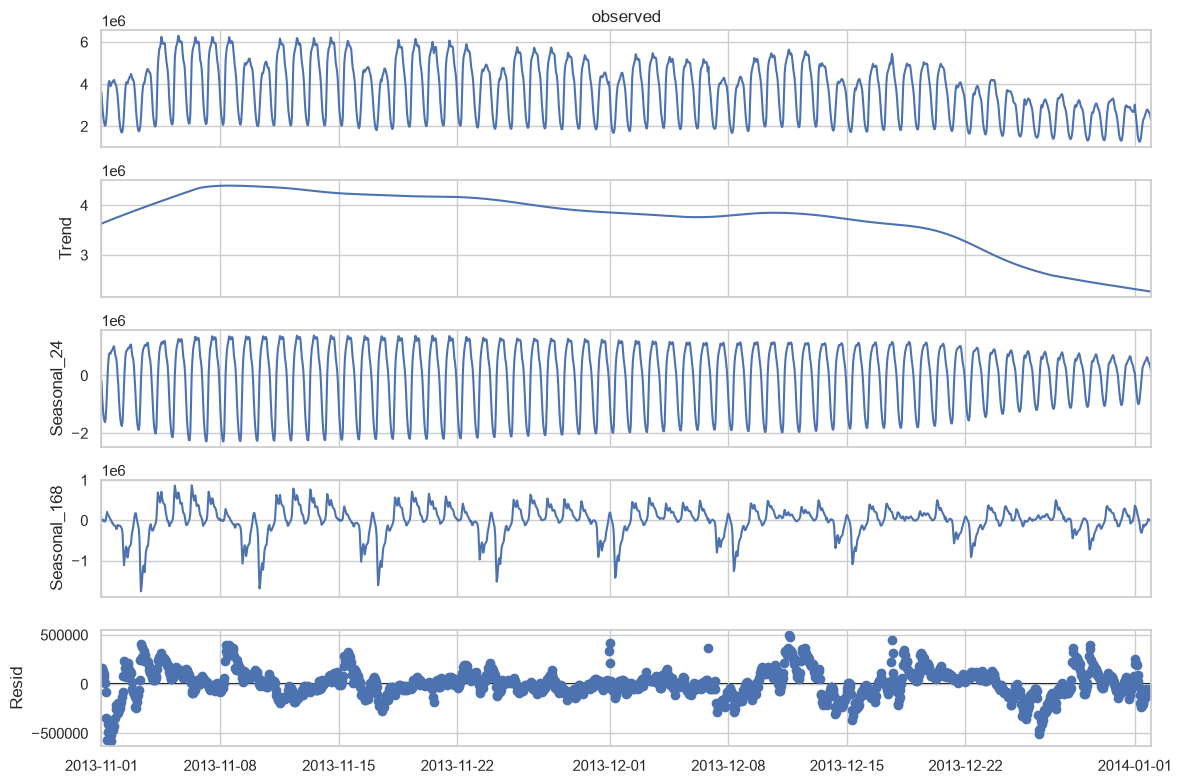

In [16]:
x = s.interpolate(limit_direction="both")
if len(x) >= 2 * 168:
    from statsmodels.tsa.seasonal import MSTL
    res = MSTL(x, periods=(24, 168)).fit()
    print("Décomposition MSTL (24 h et 168 h)")
else:
    res = STL(x, period=24, robust=True).fit()
    print("Décomposition STL (24 h) : trop peu de données pour la saisonnalité hebdomadaire")
fig = res.plot(); fig.set_size_inches(12, 8); fig.tight_layout()
fig.savefig(FIG / "04_decomposition.png", dpi=150)

resid = res.resid
strength = 1 - resid.var() / (x - res.trend).var()
print(f"Force de la saisonnalité (journalière + hebdomadaire) : {strength:.2f}")

## 5. Stationnarité et autocorrélation
Une série avec forte saisonnalité n'est pas stationnaire. Le test ADF et les ACF/PACF guident le choix des ordres de SARIMA (issue SARIMA).

C:\Users\Cheick\AppData\Local\Temp\ipykernel_15976\3411314279.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, *_ = adfuller(series.dropna())
C:\Users\Cheick\AppData\Local\Temp\ipykernel_15976\3411314279.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, *_ = adfuller(series.dropna())


Série brute : statistique ADF = -2.14, p-value = 0.2298
Après différenciation saisonnière (24 h) : statistique ADF = -5.28, p-value = 0.0000


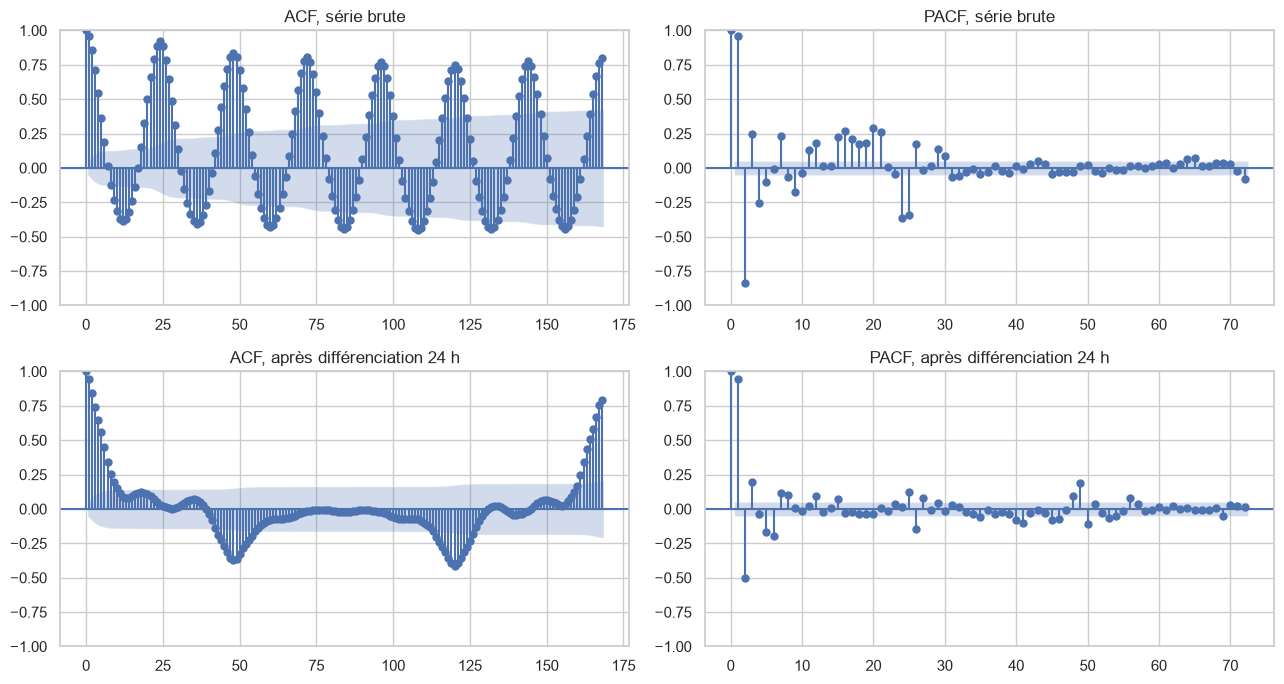

In [17]:
def adf(series, label):
    stat, p, *_ = adfuller(series.dropna())
    print(f"{label} : statistique ADF = {stat:.2f}, p-value = {p:.4f}")

adf(x, "Série brute")
adf(x.diff(24), "Après différenciation saisonnière (24 h)")

def n_lags(n, cap):
    return max(1, min(cap, n // 2 - 1))

xs = x.dropna()
d24 = x.diff(24).dropna()
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
plot_acf(xs, lags=n_lags(len(xs), 168), ax=axes[0, 0]); axes[0, 0].set_title("ACF, série brute")
plot_pacf(xs, lags=n_lags(len(xs), 72), ax=axes[0, 1], method="ywm"); axes[0, 1].set_title("PACF, série brute")
plot_acf(d24, lags=n_lags(len(d24), 168), ax=axes[1, 0]); axes[1, 0].set_title("ACF, après différenciation 24 h")
plot_pacf(d24, lags=n_lags(len(d24), 72), ax=axes[1, 1], method="ywm"); axes[1, 1].set_title("PACF, après différenciation 24 h")
fig.tight_layout(); fig.savefig(FIG / "05_acf_pacf.png", dpi=150)

## 6. Valeurs manquantes et anomalies
On repère les heures dont le résidu STL/MSTL est extrême (écart de plus de 4 écarts robustes, basés sur la médiane absolue des écarts) et on les rapproche des jours fériés italiens et de la fête de Sant'Ambrogio à Milan.

In [18]:
r = resid.dropna()
robust_sd = 1.4826 * (r - r.median()).abs().median()
anom = r[(r - r.median()).abs() > 4 * robust_sd]
print(f"{len(anom)} heures atypiques sur {len(r)}")
display(anom.to_frame("résidu").assign(date=anom.index.date).groupby("date")["résidu"].agg(["count", "mean"]))

fetes = pd.to_datetime(["2013-11-01", "2013-12-07", "2013-12-08", "2013-12-25", "2013-12-26"]).date
present = [d for d in fetes if d in set(s.index.date)]
print("Jours fériés ou fêtes locales présents dans les données :", present)

14 heures atypiques sur 1488


,count,mean
date,,
2013-11-01,8,-495249.835371
2013-12-11,2,490510.520480
2013-12-17,1,445456.002006
2013-12-26,3,-476332.580276


Jours fériés ou fêtes locales présents dans les données : [datetime.date(2013, 11, 1), datetime.date(2013, 12, 7), datetime.date(2013, 12, 8), datetime.date(2013, 12, 25), datetime.date(2013, 12, 26)]


## 7. Conclusions de l'exploration
* Saisonnalités fortes : cycle journalier (creux vers 5 h, montée entre 7 h et 8 h, plateau de 12 h à 18 h en semaine) et cycle hebdomadaire (niveau plus bas et montée du matin décalée d'environ 2 h le week-end).
* Série non stationnaire (ADF p = 0,23), stationnaire après différenciation à 24 h (p ≈ 0). La corrélation au retard 168 reste forte : la saisonnalité hebdomadaire n'est pas éliminée.
* Tendance baissière sur la période, nette après le 22 décembre. Cause non établie.
* Amplitude du cycle journalier décroissante avec le niveau : transformation logarithmique à tester.
* 14 heures atypiques sur 1 488 : 11 liées à des jours fériés (1er novembre, 26 décembre), 3 positives non expliquées (11 et 17 décembre).
* Traitement : aucune suppression, variable jour férié, évaluation principale par la MAE.